Partie 1 : Jeu de données Breast Cancer
Q1. Chargement des données
1. Importez l’ensemble de données Breast Cancer avec load_breast_cancer
de sklearn.datasets.
2. Affichez la forme des données (nombre d’échantillons, nombre de
caractéristiques).
3. Affichez les noms des caractéristiques à l’aide de feature_names.

In [36]:
import numpy as np
from sklearn import datasets
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.datasets import load_breast_cancer


In [3]:
cancer = load_breast_cancer()

In [4]:
print(cancer.data.shape)


(569, 30)


In [47]:
cancer.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

Q2. Préparation des données
4. Importez les bibliothèques numpy et pandas.
5. Créez un DataFrame nommé breast_df contenant les 30
caractéristiques.
6. Ajoutez une colonne nommée diagnostic contenant les étiquettes (0 :
bénin, 1 : malin).

In [8]:
breast_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)

In [ ]:
#breast_df['diagnosis'] = cancer.target
#breast_df.head()

In [13]:
#in the dataaet 0 is maligne and 1 is benin, so i did a reverse encoding
breast_df['diagnosis'] = 1 - cancer.target
breast_df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [14]:
breast_df.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,1
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,1
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,1
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,1
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,0


Q3. Normalisation
7.
Pourquoi est-il nécessaire de normaliser les données avant d’appliquer
une ACP ?


REPONSE: La normalisation est necessaire avant PCA parceque car elle est sensible à l'échelle des variables.


8. Utilisez StandardScaler de sklearn.preprocessing pour normaliser les
données (sans la colonne diagnostic).

In [19]:
scaler = StandardScaler()
features = breast_df.drop('diagnosis',axis=1)
scaled_features = scaler.fit_transform(features)

Q4. Application de l’ACP
9. Appliquez une ACP sur les données normalisées pour réduire la
dimension à 2 composantes principales.
10. Affichez la proportion de variance expliquée par chaque composante.
11. Affichez la somme de la variance expliquée (cumulative).

In [20]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_features)

In [22]:
print("variance expliquée par chaque composante: ",pca.explained_variance_ratio_)

variance expliquée par chaque composante:  [0.44272026 0.18971182]


In [23]:
print("somme de la variance expliquée:",sum(pca.explained_variance_ratio_))

somme de la variance expliquée: 0.6324320765155944


Q5. Visualisation
12. Créez un DataFrame contenant les deux composantes principales et la
colonne diagnostic.
13. Tracez un nuage de points (scatter plot) où :
● l’axe x est la première composante principale
● l’axe y est la deuxième composante principale
● les couleurs représentent les classes (bénin/malin)

NB: PC1 = composante principale 1


PC2 = composante principale 2


In [24]:
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['diagnosis'] = breast_df['diagnosis']

<Figure size 800x600 with 0 Axes>

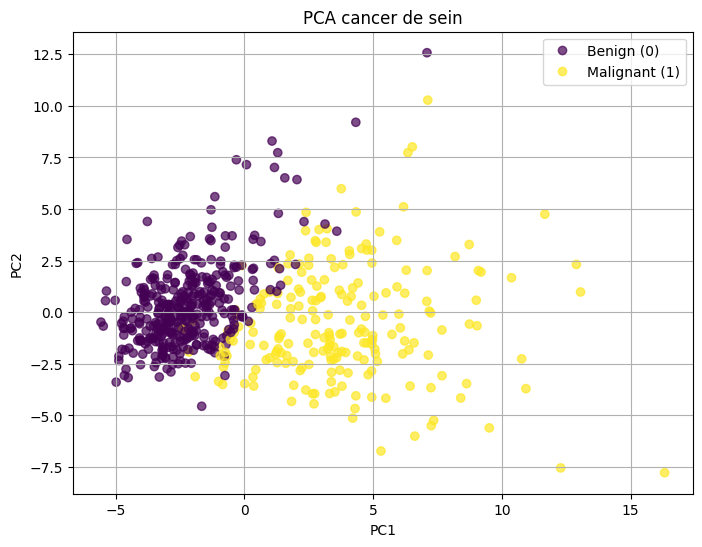

In [29]:
plt.figure(figsize=(8,6))
plt.figure(figsize=(8,6))
scatter = plt.scatter(pca_df['PC1'],pca_df['PC2'],
                      c = pca_df['diagnosis'],cmap='viridis',
                      alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA cancer de sein')
plt.legend(handles=scatter.legend_elements()[0],
           labels=['Benign (0)','Malignant (1)'])
plt.grid()
plt.show()

Partie 2 : Jeu de données CIFAR-10 (Avancé /
Bonus)

In [30]:
from keras.datasets import cifar10

Q6. Données visuelles
14. Chargez le jeu de données CIFAR-10 à l’aide de tensorflow.keras.datasets.
15. Sélectionnez uniquement deux classes (par exemple "chat" et "chien") et
extrayez 1000 images de chaque.
16. Transformez chaque image en vecteur (flatten 32x32x3 → 3072
dimensions).
17. Normalisez les données.

In [31]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [34]:
# this dataset has 10 categories
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

In [37]:
cat_indices = np.where(y_train == 3)[0][:1000]
dog_indices = np.where(y_train == 3)[0][:1000]

selected_indices = np.concatenate([cat_indices, dog_indices])
x_selected = x_train[selected_indices]
y_selected = y_train[selected_indices].flatten()

In [39]:
y_selected = np.where(y_selected == 3, 0, 1)

In [40]:
x_flattened = x_selected.reshape(x_selected.shape[0], -1)

In [42]:
scaler = StandardScaler()
x_normalized = scaler.fit_transform(x_flattened)

Q7. ACP sur images
18. Réduisez la dimension à 50 puis à 2 via ACP.
19. Tracez un nuage de points pour visualiser la séparation entre les deux


In [43]:
pca50 = PCA(n_components=50)
x_pca50 = pca50.fit_transform(x_normalized)

In [44]:
pca2 = PCA(n_components=2)
x_pca2 = pca2.fit_transform(x_normalized)

<ipython-input-48-f00547726558>:7: UserWarning: Mismatched number of handles and labels: len(handles) = 1 len(labels) = 2
  plt.legend(handles=scatter.legend_elements()[0],


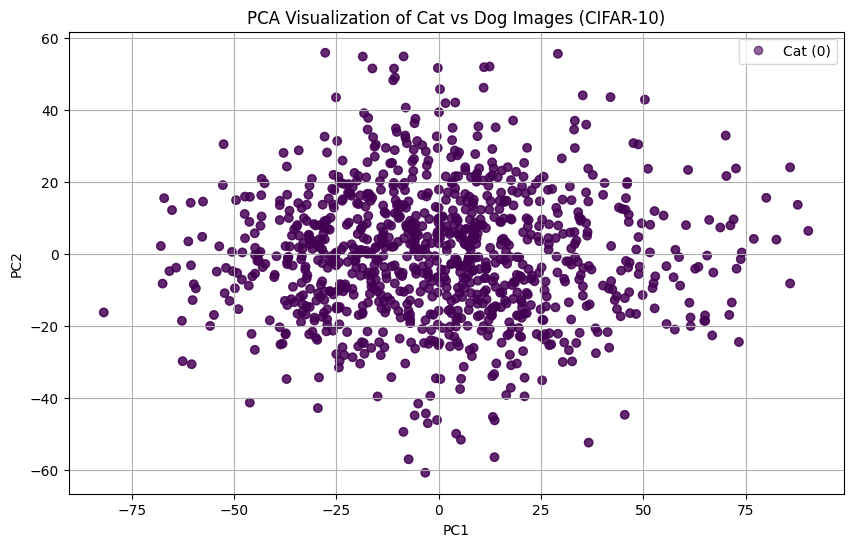

In [48]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(x_pca2[:, 0], x_pca2[:, 1], c=y_selected,
                     cmap='viridis', alpha=0.6)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Visualization of Cat vs Dog Images (CIFAR-10)')
plt.legend(handles=scatter.legend_elements()[0],
          labels=['Cat (0)', 'Dog (1)'])
plt.grid()
plt.show()

20. Commentez : l’ACP permet-elle de bien séparer les deux classes ?

REPONSE: Non l'ACP ne permet pas de separer clairement les deux classes



Questions de réflexion
21. Quelle est la principale limitation de l’ACP en classification ?


**Reponses:** La principale limitation de l'ACP est au'elle ne tient compte que de la variance des données, et non des étiquettes de classe.

22. Quelle est la différence entre une variable d’origine et une composante
principale ?


**REPONSE:** Les variables originales sont les caractéristiques brutes de l'ensemble de données. Les composantes principales sont de nouvelles variables orthogonales qui sont des combinaisons linéaires des caractéristiques originales, classées en fonction de la variance qu'elles expliquent dans les données.

23. Que signifie une variance expliquée élevée par la première composante
?


**REPONSE:** Une variance expliquée élevée dans la première composante principale signifie que cette dimension unique capture une grande partie de la variabilité des données. Cela suggère que de nombreuses caractéristiques originales sont corrélées et peuvent être résumées efficacement par cette seule composante.

24. Donnez un exemple de cas où l’ACP ne serait pas appropriée.


**REPONSE:** - Données avec des relations non linéaires entre les caractéristiques .